In [1]:
from pathlib import Path
import sys
import importlib

# Locate the capsule/project root independently of the working directory.
# In Code Ocean this notebook lives in /code/<subfolder>/ and the data in /data.
# Locally it lives in <repo>/code/<subfolder>/ with the data in <repo>/data.
def _find_code_dir(start):
    for p in [start, *start.parents]:
        if (p / "utils.py").is_file():
            return p
        if (p / "code" / "utils.py").is_file():
            return p / "code"
    raise FileNotFoundError("could not find code/utils.py")

CODE_DIR = _find_code_dir(Path.cwd().resolve())
DATA_DIR = CODE_DIR.parent / "data"
# Add the code folder to sys.path so that `utils`, `statistic_checks` and
# `mot_analysis` can be imported
sys.path.append(str(CODE_DIR))

import pandas as pd
import numpy as np
import utils
importlib.reload(utils)

<module 'utils' from 'C:\\Users\\idol\\Desktop\\bigProjects\\EyeTrackingAnalysis\\utils.py'>

In [2]:
from statistic_checks import GLMs, MixedEffectStatistics, plot_utils, article_plots
importlib.reload(article_plots)

Error importing in API mode: ImportError('On Windows, cffi mode "ANY" is only "ABI".')
Trying to import in ABI mode.


<module 'statistic_checks.article_plots' from 'C:\\Users\\idol\\Desktop\\bigProjects\\EyeTrackingAnalysis\\statistic_checks\\article_plots.py'>

In [3]:
# 4. MOT: Tracking Accuracy
mot_acc_stats = {
    "p-value": ".033 *",
    "β (Estimate)": "-0.453",
    "Note": "Odds ratio: 0.623"
}

# 5. MOT: Saccade Duration
mot_sacc_stats = {
    "p-value": ".008 **",
    "β (Estimate)": "4.5 ms",
}

# 6. MOT: Distance from Centroid
mot_dist_stats = {
    "p-value": ".008 **",
    "β (Estimate)": "175.84 px",
    "Note": "1.88° visual angle"
}

path_length_stats = {
    "p-value": ".001 **",
    "β (Estimate)": "658.08 px",
    "Note": "7.05° visual angle"
}

### Performance

In [4]:
performance_df = pd.read_csv(DATA_DIR / "mot_long_dataframe.csv")
performance_df = performance_df[~((performance_df["participant_id"] == 0))].reset_index(drop=True)
performance_df = performance_df[~((performance_df["trial_id"] == 0))].reset_index(drop=True)

performance_df["group"] = performance_df["group"].replace("Experienced", "ATCs")
performance_df["group"] = performance_df["group"].replace("Experts", "ATCs")
performance_df["condition"] = performance_df["trial_id"] // 3
performance_df = performance_df[performance_df["condition"] != 11]


C:\Users\idol\Desktop\bigProjects\EyeTrackingAnalysis\statistic_checks\article_plots.py:310: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


Means - Novices: 0.653, ATCs: 0.743 | Linear Diff: -0.091 | % Diff: -13.92%


C:\Users\idol\Desktop\bigProjects\EyeTrackingAnalysis\statistic_checks\article_plots.py:147: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([condition_mapping[cond] for cond in x_order], fontsize=TICK_FONT_SIZE)


emp_logit:
{'group_coef': -0.4532746972928618, 'group_p_value': 0.03331, 'marginal_r2': np.float64(0.3901527288426617), 'conditional_r2': np.float64(0.5580472070866928)}


C:\Users\idol\Desktop\bigProjects\EyeTrackingAnalysis\statistic_checks\article_plots.py:310: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


Means - Novices: 0.689, ATCs: 1.143 | Linear Diff: -0.453 | % Diff: -65.75%


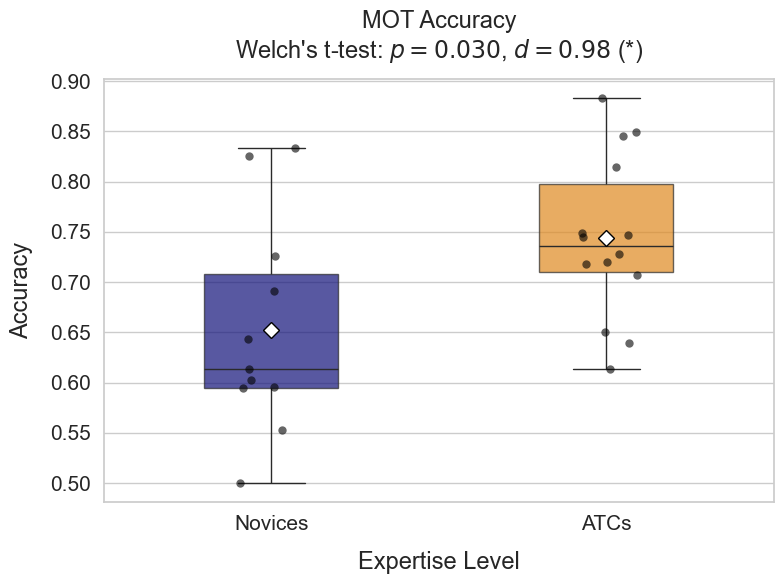

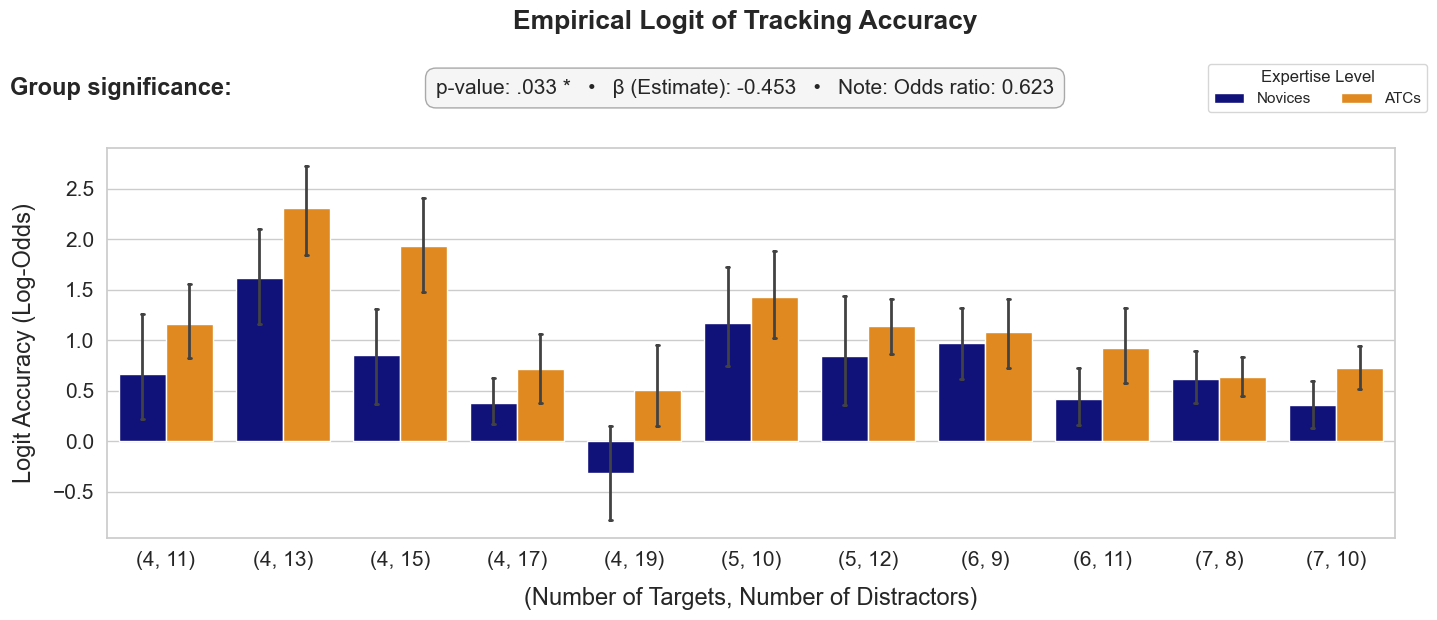

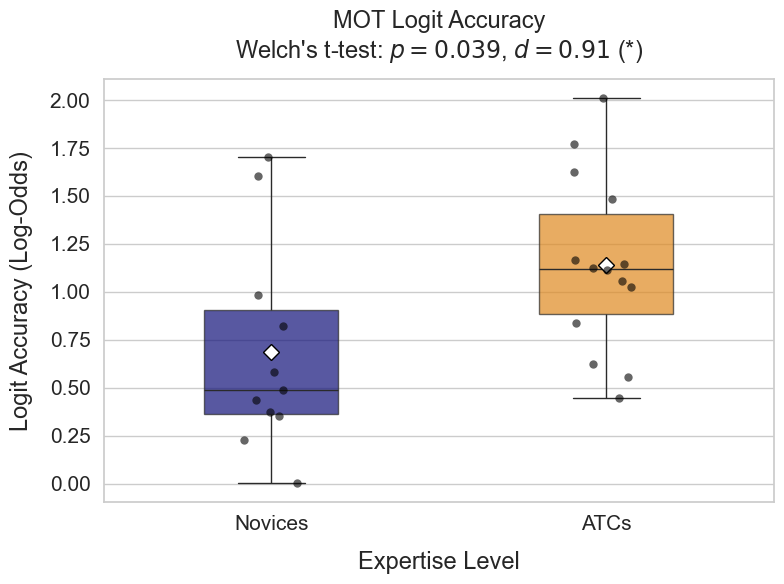

In [5]:
importlib.reload(article_plots)
# 1. Add 'group' to the groupby. 
agg_df = performance_df.groupby(['participant_id', 'group', 'condition'])[['correct', 'num_targets']].sum().reset_index()

# 2. Calculate the misses
misses = agg_df['num_targets'] - agg_df['correct']

# 3. Apply empirical logit formula
agg_df['accuracy'] = agg_df['correct'] / agg_df['num_targets']
# Filter for the ATC group and calculate the mean of the 'accuracy' column
atc_mean_accuracy = agg_df[agg_df['group'] == 'Novices']['accuracy'].mean()

fig, ax, _= article_plots.plot_aggregated_feature(
    df=agg_df, 
    feature_col='accuracy', 
    y_label='Accuracy', 
    plot_title='MOT Accuracy'
)
# fig.savefig("../figures/aggregated_features/mot_accuracy.png", dpi=300, bbox_inches='tight')



agg_df['emp_logit'] = np.log((agg_df['correct'] + 0.5) / (misses + 0.5))



# 4. Filter down to the final requested columns, now including group
final_df = agg_df[['participant_id', 'group', 'condition', 'emp_logit', 'accuracy']]

fig, ax = article_plots.plot_mot_feature(final_df, 'emp_logit', 
                               plot_title="Empirical Logit of Tracking Accuracy", 
                               y_label="Logit Accuracy (Log-Odds)",
                               stat_box=mot_acc_stats)
# fig.savefig("../figures/features_per_condition/mot_logit_accuracy.png", dpi=300, bbox_inches='tight')
model, extras = GLMs.run_pymer_lmm(final_df, 'emp_logit', interaction_term="+")
print("emp_logit:")
print(extras)

fig, ax, per_participant_logit_accuracy = article_plots.plot_aggregated_feature(
    df=final_df, 
    feature_col='emp_logit',  # Change this if your dataframe uses a different column name for the logit values
    y_label='Logit Accuracy (Log-Odds)', 
    plot_title='MOT Logit Accuracy'
)
# fig.savefig("../figures/aggregated_features/mot_logit_accuracy.png", dpi=300, bbox_inches='tight')


In [6]:
# importlib.reload(GLMs)
# importlib.reload(article_plots)
# per_participant_accuracy = GLMs.extract_lmm_participant_scores(final_df, 'emp_logit')
# fig, ax = article_plots.plot_aggregated_feature(per_participant_accuracy, 'emp_logit_zscore', 'Accuracy Z-Score', 'Adjusted MOT Accuracy (Log-Odds)')
# fig.savefig("../figures/z_scores/mot_accuracy_z_score.png", dpi=300, bbox_inches='tight')

### Saccade Duration

In [7]:
import re
simple_df = pd.read_csv(DATA_DIR / "simple_df_mot.csv")

simple_df = simple_df.rename(columns={"pid":"participant_id"})
simple_df = simple_df[~((simple_df["participant_id"] == 0))].reset_index(drop=True)
simple_df = simple_df[~((simple_df["trial_id"] == 0))].reset_index(drop=True)

simple_df["group"] = simple_df["group"].replace("Experienced", "ATCs")
simple_df["group"] = simple_df["group"].replace("Experts", "ATCs")
simple_df["condition"] = simple_df["trial_id"] // 3
simple_df = simple_df[simple_df["condition"] != 11]

def clean_coordinate_strings(coord):
    """Extracts x and y float values from a string representation."""
    # If it's already a proper list or tuple, leave it alone
    if isinstance(coord, (list, tuple)):
        return coord
        
    if isinstance(coord, str):
        # Find all numbers that contain a decimal point
        floats = re.findall(r"[-+]?\d+\.\d+", coord)
        if len(floats) >= 2:
            return (float(floats[0]), float(floats[1]))
            
    return (np.nan, np.nan)

# Apply this to your DataFrame before running any plotting or summary functions:
simple_df['start_pos'] = simple_df['start_pos'].apply(clean_coordinate_strings)
simple_df['end_pos'] = simple_df['end_pos'].apply(clean_coordinate_strings)

In [8]:
# 1. Filter for saccades and create a clean copy
sac_df = simple_df[simple_df['event_type'] == 'saccade'].copy()
sac_df['duration_ms'] = 1000 * sac_df['duration_sec']
# 2. Filter by duration
sac_df = sac_df[sac_df["duration_sec"] > 0.015]

# 3. Unpack the tuples into temporary x and y columns
# This assumes start_pos and end_pos are (x, y)
sac_df[['sx', 'sy']] = pd.DataFrame(sac_df['start_pos'].tolist(), index=sac_df.index)
sac_df[['ex', 'ey']] = pd.DataFrame(sac_df['end_pos'].tolist(), index=sac_df.index)

# 4. Calculate Amplitude in Pixels (Euclidean Distance)
sac_df["amp_px"] = np.sqrt((sac_df['ex'] - sac_df['sx'])**2 + 
                           (sac_df['ey'] - sac_df['sy'])**2)

# 5. Convert Pixels to Degrees
sac_df["amp_deg"] = utils.pixels_to_degrees(sac_df['amp_px'])

# 6. Apply the Amplitude Threshold (0.5 degrees)
sac_df = sac_df[sac_df['amp_deg'] > 1]

# Clean up temporary coordinate columns if you don't need them
sac_df = sac_df.drop(columns=['sx', 'sy', 'ex', 'ey'])

### Bimodal Analysis Of Saccade Duration

In [9]:
import pandas as pd
import numpy as np
from scipy.stats import gaussian_kde
from scipy.signal import find_peaks

def find_group_threshold(durations):
    # Filter data to the relevant range (0-200ms) as per the paper [cite: 225]
    clean_data = durations[durations < 0.2] 
    if len(clean_data) < 10: return 0.032
    
    kde = gaussian_kde(clean_data)
    x = np.linspace(0, 0.2, 500)
    y = kde(x)
    
    peaks, _ = find_peaks(y)
    if len(peaks) < 2:
        return 0.032 # Fallback to paper's consistent Lm [cite: 379]
    
    # Find valley between first two peaks
    valley_region = y[peaks[0]:peaks[1]]
    valley_index = np.argmin(valley_region) + peaks[0]
    return x[valley_index]

def aggregate_with_dynamic_thresholds(df, thresh_map):
    # 1. Identify group name (handles cases where 'group' col is dropped/indexed)
    group_name = df.name if hasattr(df, 'name') else df['group'].iloc[0]
    L_m = thresh_map.get(group_name, 0.032)
    
    # 2. Prepare helper columns to make aggregation reliable
    # We create copies of the duration column filtered by the threshold
    df = df.copy()
    is_short = df['duration_sec'] <= L_m
    df['dur_short'] = df['duration_sec'].where(is_short)
    df['dur_long'] = df['duration_sec'].where(~is_short)
    df['is_short_int'] = is_short.astype(int)
    
    # 3. Aggregate by participant
    # Note: Every entry is a (SourceColumn, Function) tuple
    agg = df.groupby('participant_id').agg(
        prop_short=('is_short_int', 'mean'),
        mean_duration_short=('dur_short', 'mean'),
        mean_duration_long=('dur_long', 'mean')
    )
    
    # 4. Add the group-level info back
    agg['group'] = group_name
    agg['dynamic_threshold'] = L_m
    
    return agg

# --- Execution ---

# Calculate thresholds per group first
thresholds = sac_df.groupby('group')['duration_sec'].apply(find_group_threshold).to_dict()

# Calculate the combined threshold for the entire dataset
combined_threshold = find_group_threshold(sac_df['duration_sec'])

# Apply the fixed aggregation
# include_groups=False prevents 'group' column from causing conflicts in newer pandas
aggregated_results = sac_df.groupby('group').apply(
    lambda x: aggregate_with_dynamic_thresholds(x, thresholds)
).reset_index(drop=True)

# Print the results
print("Calculated Thresholds (Lm) per group:", thresholds)
print(f"Calculated Combined Threshold (Lm): {combined_threshold}")

Calculated Thresholds (Lm) per group: {'ATCs': 0.030460921843687375, 'Novices': 0.0312625250501002}
Calculated Combined Threshold (Lm): 0.030861723446893786


C:\Users\idol\AppData\Local\Temp\ipykernel_1788\3893513156.py:61: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  aggregated_results = sac_df.groupby('group').apply(


C:\Users\idol\Desktop\bigProjects\EyeTrackingAnalysis\statistic_checks\article_plots.py:310: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


Means - Novices: 0.266, ATCs: 0.290 | Linear Diff: -0.024 | % Diff: -8.98%


C:\Users\idol\Desktop\bigProjects\EyeTrackingAnalysis\statistic_checks\article_plots.py:310: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
C:\Users\idol\Desktop\bigProjects\EyeTrackingAnalysis\statistic_checks\article_plots.py:310: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


Means - Novices: 0.024, ATCs: 0.023 | Linear Diff: 0.000 | % Diff: 1.70%
Means - Novices: 53.662, ATCs: 47.874 | Linear Diff: 5.788 | % Diff: 10.79%
Novices: 53.7 ms
ATCs: 47.9 ms
Difference: 5.8 ms


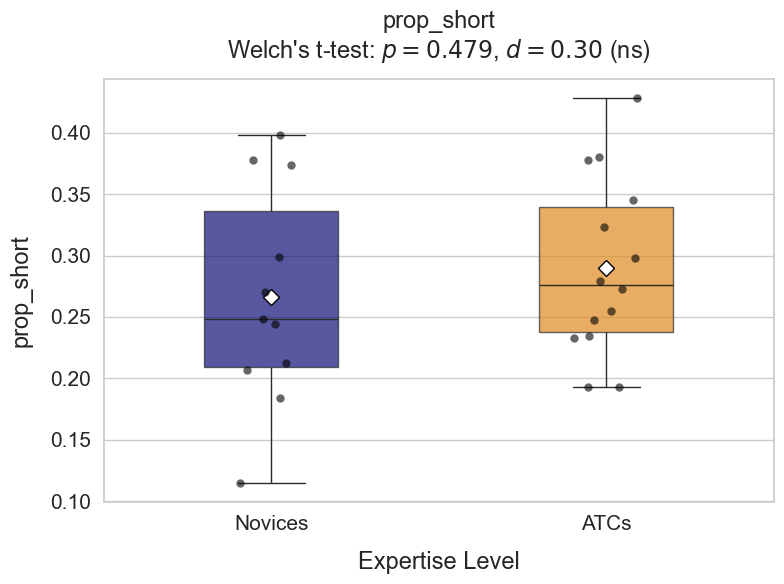

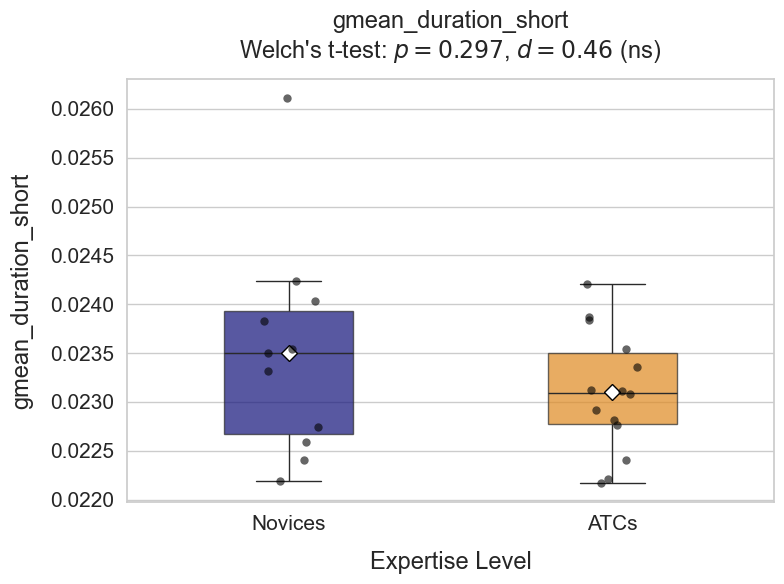

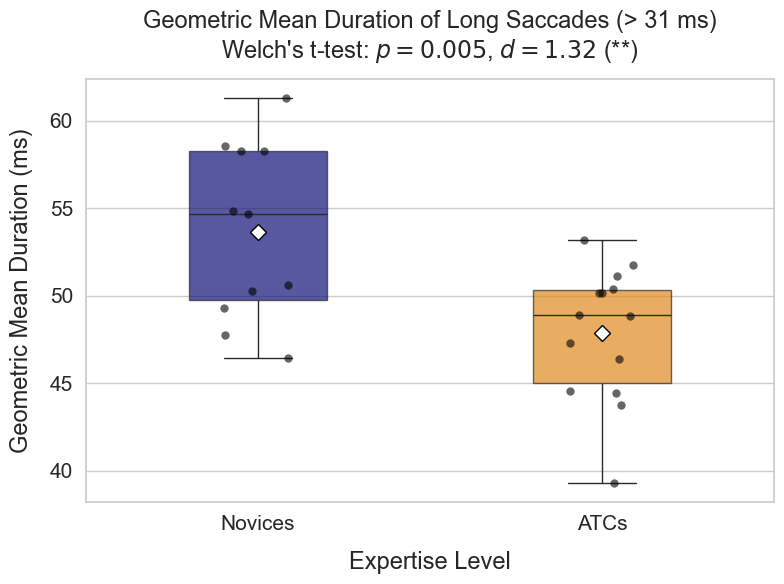

In [10]:
import pandas as pd
import numpy as np
from scipy.stats import gmean

# We use the 31ms threshold derived from your data
THRESHOLD = 0.031 

def aggregate_bimodal_saccades(df):
    # 1. Classify each saccade as Short or Long
    df['is_short'] = df['duration_sec'] <= THRESHOLD
    
    # 2. Define the aggregation logic per participant
    agg_df = df.groupby(['participant_id', 'group']).agg(
        total_saccades=('duration_sec', 'count'),
        # Overall gmean (for reference, though paper suggests it's less representative)
        gmean_duration_global=('duration_sec', gmean),
        # Proportion of short saccades (reflects bottom-up vs top-down balance)
        prop_short=('is_short', 'mean')
    ).reset_index()
    
    # 3. Calculate separate geometric means for the two peaks
    short_gmeans = df[df['is_short']].groupby('participant_id')['duration_sec'].apply(gmean).rename('gmean_duration_short')
    long_gmeans = df[~df['is_short']].groupby('participant_id')['duration_sec'].apply(gmean).rename('gmean_duration_long')
    
    # 4. Merge peak-specific gmeans back to the main aggregated dataframe
    agg_df = agg_df.merge(short_gmeans, on='participant_id', how='left')
    agg_df = agg_df.merge(long_gmeans, on='participant_id', how='left')
    
    return agg_df

# Run the aggregation
participant_summary = aggregate_bimodal_saccades(sac_df)

article_plots.plot_aggregated_feature(participant_summary, 'prop_short', 'prop_short', 'prop_short')
article_plots.plot_aggregated_feature(participant_summary, 'gmean_duration_short', 'gmean_duration_short', 'gmean_duration_short')
participant_summary["gmean_duration_long_ms"] = 1000 * participant_summary["gmean_duration_long"]

fig, ax, per_participant_sac_dur= article_plots.plot_aggregated_feature(
    df=participant_summary, 
    feature_col='gmean_duration_long_ms', 
    y_label='Geometric Mean Duration (ms)', 
    plot_title='Geometric Mean Duration of Long Saccades (> 31 ms)'
)
# fig.savefig("../figures/aggregated_features/sac_dur_long_gmean.png", dpi=300, bbox_inches='tight')
# Calculate the exact group means of the geometric means in milliseconds
long_gmeans_ms = participant_summary.groupby('group')['gmean_duration_long'].mean() * 1000

# Calculate the difference
diff = long_gmeans_ms['Novices'] - long_gmeans_ms['ATCs']

print(f"Novices: {long_gmeans_ms['Novices']:.1f} ms")
print(f"ATCs: {long_gmeans_ms['ATCs']:.1f} ms")
print(f"Difference: {diff:.1f} ms")

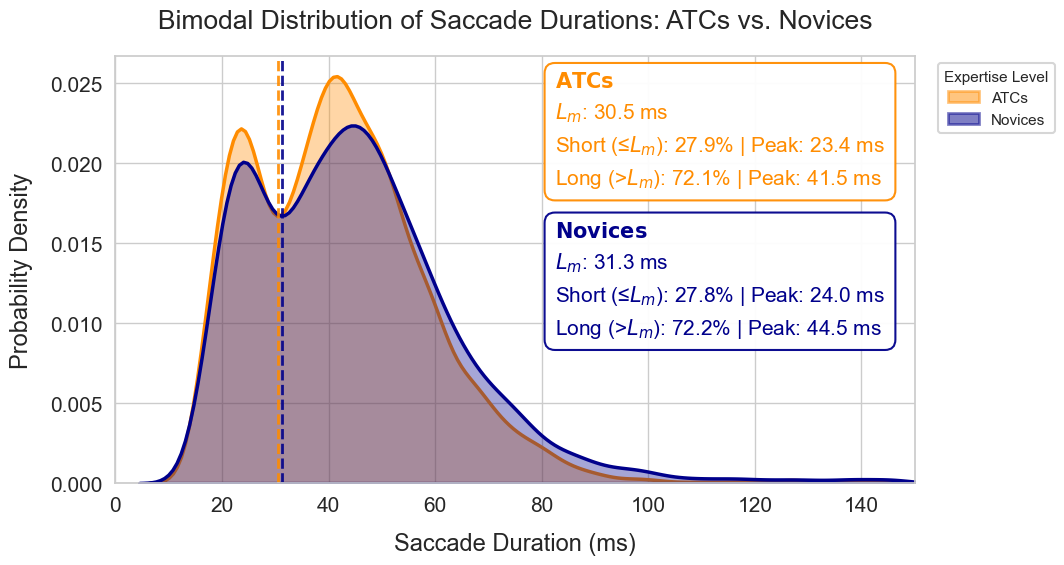

In [11]:
importlib.reload(article_plots)
fig, ax = article_plots.plot_bimodal_saccade_distribution(sac_df, thresholds)
# fig.savefig("../figures/others/bimodal_distribution_sac_dur.png", dpi=300, bbox_inches='tight')

C:\Users\idol\Desktop\bigProjects\EyeTrackingAnalysis\statistic_checks\article_plots.py:147: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([condition_mapping[cond] for cond in x_order], fontsize=TICK_FONT_SIZE)


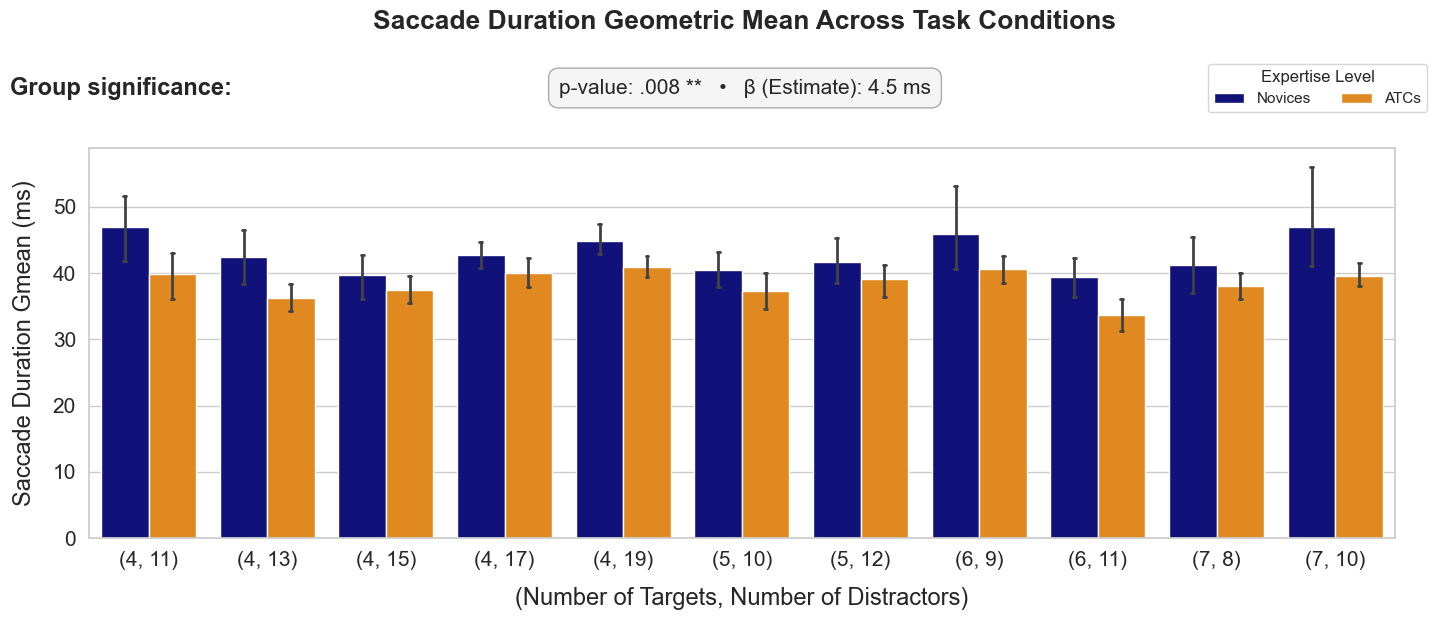

In [12]:
from scipy.stats import gmean
importlib.reload(GLMs)
from statistic_checks import plot_utils, article_plots, MixedEffectStatistics
importlib.reload(article_plots)
col_name = "duration_ms"
agg_func = gmean
func_name = agg_func.__name__
val_col_name = f"{func_name}_{col_name}"
df_agg = MixedEffectStatistics.condition_aggregator(
        df=sac_df,  
        value_col=col_name, 
        agg_func= agg_func
    )

fig, ax = article_plots.plot_mot_feature(
    df=df_agg, 
    feature=val_col_name, 
    y_label="Saccade Duration Gmean (ms)",  
    plot_title="Saccade Duration Geometric Mean Across Task Conditions",
    stat_box=mot_sacc_stats
)
# fig.savefig("../figures/features_per_condition/mot_saccade_duration_gmean.png", dpi=300, bbox_inches='tight')



In [13]:
from scipy.stats import gmean, trim_mean, skew, kurtosis

# Factory function to generate specific trimmed means
def create_trimmed_aggregator(proportion):
    def custom_trim(x):
        # scipy's trim_mean cuts 'proportion' from BOTH ends
        return trim_mean(x, proportiontocut=proportion)
    # Dynamically set the function's name for your condition_aggregator
    pct = int(proportion * 100)
    custom_trim.__name__ = f"trimmed_mean_{pct}pct"
    
    return custom_trim# 1. Define all your aggregators in a list
aggregators = [
    np.mean, 
    np.median, 
    gmean, 
    create_trimmed_aggregator(0.1),
    create_trimmed_aggregator(0.2),
    create_trimmed_aggregator(0.3),
    np.std, skew]

In [14]:
from statistic_checks import GLMs, MixedEffectStatistics
from scipy.stats import gmean
importlib.reload(GLMs)

GLMs.aggregators_pipeline(sac_df, "duration_ms", aggregators, weight_method = "log_count", interaction_term="+")


C:\Users\idol\Desktop\bigProjects\EyeTrackingAnalysis\statistic_checks\GLMs.py:103: FutureWarning: The provided callable <function mean at 0x0000016FA93827A0> is currently using SeriesGroupBy.mean. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "mean" instead.
  agg_df = df.groupby(group_cols)[value_col].agg(agg_func).reset_index()
C:\Users\idol\Desktop\bigProjects\EyeTrackingAnalysis\statistic_checks\GLMs.py:103: FutureWarning: The provided callable <function median at 0x0000016FA94F40D0> is currently using SeriesGroupBy.median. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "median" instead.
  agg_df = df.groupby(group_cols)[value_col].agg(agg_func).reset_index()
C:\Users\idol\Desktop\bigProjects\EyeTrackingAnalysis\statistic_checks\GLMs.py:103: FutureWarning: The provided callable <function std at 0x0000016FA93828C0> is currently using SeriesGro

                    group_coef  group_p_value  marginal_r2  conditional_r2
aggregator                                                                
mean                    8.4864         0.0022       0.1861          0.2591
median                  2.7665         0.1055       0.1560          0.2410
gmean                   4.5006         0.0079       0.1752          0.2612
trimmed_mean_10pct      4.7829         0.0107       0.1753          0.2368
trimmed_mean_20pct      3.3487         0.0465       0.1633          0.2402
trimmed_mean_30pct      3.0642         0.0704       0.1590          0.2419
std                    14.6569         0.0054       0.1791          0.2633
skew                    0.8266         0.0100       0.1770          0.2310


,group_coef,group_p_value,marginal_r2,conditional_r2
aggregator,,,,
mean,8.4864,0.0022,0.1861,0.2591
median,2.7665,0.1055,0.1560,0.2410
gmean,4.5006,0.0079,0.1752,0.2612
trimmed_mean_10pct,4.7829,0.0107,0.1753,0.2368
trimmed_mean_20pct,3.3487,0.0465,0.1633,0.2402
trimmed_mean_30pct,3.0642,0.0704,0.1590,0.2419
std,14.6569,0.0054,0.1791,0.2633
skew,0.8266,0.0100,0.1770,0.2310


In [15]:
# weight_agg_df = GLMs.weighted_condition_aggregator(sac_df, "duration_sec", weight_method = "log_count", agg_func=gmean)

# per_participant_saccade_dur = GLMs.extract_lmm_participant_scores(weight_agg_df, "gmean_duration_sec", weight_col= "weight")
# # per_participant_saccade_dur = utils.aggregate_global_feature(sac_df, "duration_sec", agg_func=gmean)

# fig, ax = article_plots.plot_aggregated_feature(per_participant_saccade_dur, 'gmean_duration_sec_zscore', 'Saccade Duration Z-Score', 'Adjusted MOT Saccade Duration')
# fig.savefig("../figures/z_scores/sac_dur_z_score.png", dpi=300, bbox_inches='tight')

### Centroid Looking

In [16]:
# 1. Load the full movement phase data
# (Assuming you updated your saving script to use this name/extension)
file_path = DATA_DIR / "movement_phase_full.pkl"
combined_df = pd.read_pickle(file_path)
combined_df = combined_df[~((combined_df["participant_id"] == 0))].reset_index(drop=True)
combined_df = combined_df[~((combined_df["trial_id"] == 0))].reset_index(drop=True)

combined_df["group"] = combined_df["group"].replace("Experienced", "ATCs")
combined_df["group"] = combined_df["group"].replace("Experts", "ATCs")

In [ ]:
import pandas as pd
import numpy as np
import math
from scipy.stats import gmean
from mot_analysis import mot_helpers


def get_raw_distances(row, centroid_lists, interval_sec=1, fps=30):
    trial_idx = int(row["trial_id"])
    trial_centroids = centroid_lists[trial_idx] 
    
    num_samples = int(interval_sec * 1000)
    x_samples = row["xpos"][:num_samples]
    y_samples = row["ypos"][:num_samples]
    
    distances = []
    
    for i, (x, y) in enumerate(zip(x_samples, y_samples)):
        if np.isnan(x) or np.isnan(y):
            continue
            
        frame_idx = int((i / 1000.0) * fps)
        
        if frame_idx < len(trial_centroids):
            _, target_centroid = trial_centroids[frame_idx]
            dist = math.dist((x, y), target_centroid)
            distances.append(dist)
            
    # Return the raw array of distances, or NaN if empty
    return np.array(distances) if distances else np.nan

def get_raw_distances_denoised(row, centroid_lists, interval_sec=1.0, fps=30):
    trial_idx = int(row["trial_id"])
    trial_centroids = centroid_lists[trial_idx] 
    
    xpos = row["xpos"]
    ypos = row["ypos"]
    
    # Calculate how many frames we need to process
    num_frames = int(interval_sec * fps)
    distances = []
    
    for frame_idx in range(num_frames):
        # Calculate the start and end milliseconds for the current frame
        # (e.g., frame 0 is 0-33ms, frame 1 is 33-66ms)
        start_ms = int(frame_idx * 1000.0 / fps)
        end_ms = int((frame_idx + 1) * 1000.0 / fps)
        
        # Safeguard against out-of-bounds if the gaze array is shorter than expected
        if start_ms >= len(xpos):
            break
            
        # Slice the gaze data for this specific frame's time window
        frame_x = xpos[start_ms:min(end_ms, len(xpos))]
        frame_y = ypos[start_ms:min(end_ms, len(ypos))]
        
        # Calculate the gaze centroid for this frame, ignoring NaNs (blinks)
        # We suppress the warning that occurs if the entire slice is NaNs
        with np.errstate(invalid='ignore'):
            gaze_cx = np.nanmean(frame_x)
            gaze_cy = np.nanmean(frame_y)
        
        # If np.nanmean returns NaN, it means the entire frame was a blink
        if np.isnan(gaze_cx) or np.isnan(gaze_cy):
            continue
            
        # Get the target centroid for this frame and calculate distance
        if frame_idx < len(trial_centroids):
            _, target_centroid = trial_centroids[frame_idx]
            dist = math.dist((gaze_cx, gaze_cy), target_centroid)
            distances.append(dist)
            
    # Return the 30Hz array of distances, or NaN if empty
    return np.array(distances) if len(distances) > 0 else np.nan

centroid_lists = [mot_helpers.target_ball_positions_at_times(t) for t in range(36)]
combined_df["raw_distances_first_sec"] = combined_df.apply(
    lambda row: get_raw_distances(row, centroid_lists, interval_sec=0.5, fps=30), 
    axis=1
)

# 4. Define our aggregators
def rms(x): return np.sqrt(np.mean(np.square(x)))

centroid_aggregators = {
    "mean": np.mean,
    "median": np.median,
    "std": np.std,
    "percentile_90": lambda x: np.percentile(x, 90),
    "rms": rms,
    "gmean": gmean 
}

# 5. Loop through aggregators to create lightweight DataFrames
lightweight_dfs = {}

for agg_name, agg_func in centroid_aggregators.items():
    # Helper to safely apply the function only to valid arrays (ignoring NaNs)
    def safe_agg(dist_array):
        if isinstance(dist_array, float) and np.isnan(dist_array):
            return np.nan
        # gmean cannot handle zeros, add a tiny epsilon if needed, though distances are rarely exactly 0.0
        return agg_func(dist_array)

    # Create the lightweight df with just ID columns
    temp_df = combined_df[["participant_id", "group", "trial_id"]].copy()
    
    # Apply the aggregator to the raw distances and assign to the new feature column
    feature_col = f"{agg_name}_target_dist_first_sec"
    temp_df[feature_col] = combined_df["raw_distances_first_sec"].apply(safe_agg)
    
    # Store in our dictionary
    lightweight_dfs[agg_name] = temp_df


0.7494391486306472

--- Running Pipeline for tracking metric: mean ---


C:\Users\idol\Desktop\bigProjects\EyeTrackingAnalysis\statistic_checks\MixedEffectStatistics.py:20: FutureWarning: The provided callable <function mean at 0x000001E80A2F67A0> is currently using SeriesGroupBy.mean. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "mean" instead.
  )[value_col].agg(agg_func).reset_index()



--- Running Pipeline for tracking metric: median ---


C:\Users\idol\Desktop\bigProjects\EyeTrackingAnalysis\statistic_checks\MixedEffectStatistics.py:20: FutureWarning: The provided callable <function mean at 0x000001E80A2F67A0> is currently using SeriesGroupBy.mean. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "mean" instead.
  )[value_col].agg(agg_func).reset_index()



--- Running Pipeline for tracking metric: std ---


...


--- Running Pipeline for tracking metric: rms ---


C:\Users\idol\Desktop\bigProjects\EyeTrackingAnalysis\statistic_checks\MixedEffectStatistics.py:20: FutureWarning: The provided callable <function mean at 0x000001E80A2F67A0> is currently using SeriesGroupBy.mean. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "mean" instead.
  )[value_col].agg(agg_func).reset_index()
C:\Users\idol\Desktop\bigProjects\EyeTrackingAnalysis\statistic_checks\article_plots.py:147: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([condition_mapping[cond] for cond in x_order], fontsize=TICK_FONT_SIZE)
C:\Users\idol\Desktop\bigProjects\EyeTrackingAnalysis\statistic_checks\article_plots.py:310: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


Means - Novices: 679.169, ATCs: 503.333 | Linear Diff: 175.836 | % Diff: 25.89%

--- Running Pipeline for tracking metric: gmean ---


C:\Users\idol\Desktop\bigProjects\EyeTrackingAnalysis\statistic_checks\MixedEffectStatistics.py:20: FutureWarning: The provided callable <function mean at 0x000001E80A2F67A0> is currently using SeriesGroupBy.mean. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "mean" instead.
  )[value_col].agg(agg_func).reset_index()



 FINAL SUMMARY TABLE: Target Distance
   Aggregator  Coefficient(pixels)  Coefficient(degrees)  P-Value  Conditional R2  Marginal R2
         mean           157.102216              1.681979 0.010870        0.580327     0.360705
       median           150.718096              1.613629 0.015120        0.548747     0.373468
          std            78.935816              0.845108 0.001355        0.542519     0.423432
percentile_90           246.316420              2.637131 0.003711        0.595456     0.379319
          rms           175.836274              1.882551 0.007670        0.589245     0.364693
        gmean           138.977649              1.487933 0.015530        0.569669     0.358204


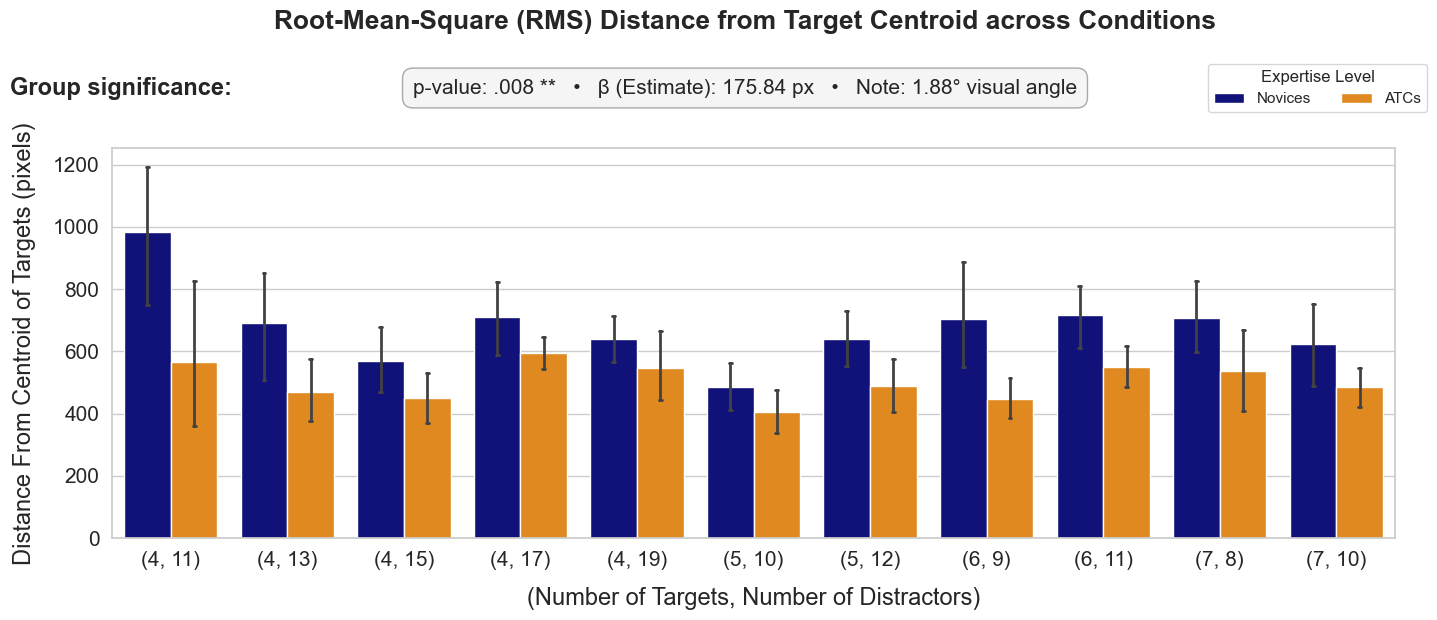

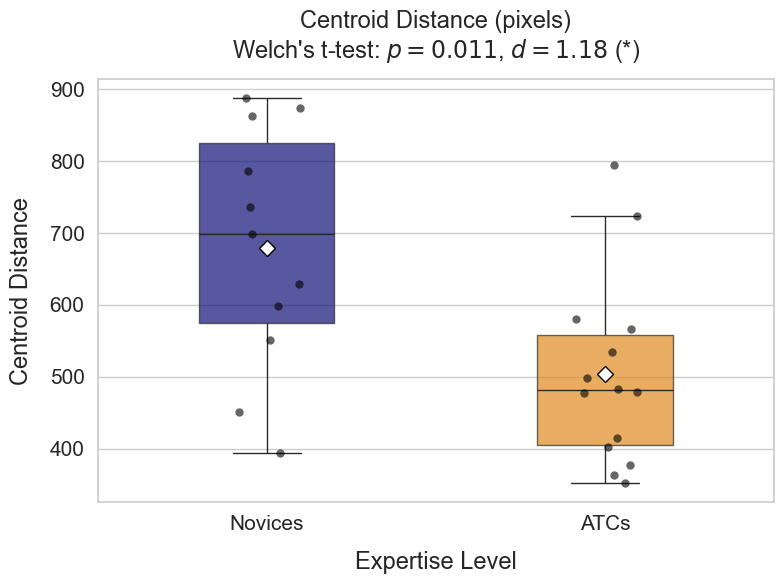

In [ ]:
import utils
importlib.reload(utils)
# List to hold the summary metrics for the final table
summary_metrics = []

# 2. Loop through each aggregator's dataframe that we created earlier
for agg_name, df_metric in lightweight_dfs.items():
    df_metric["condition"] = df_metric["trial_id"] // 3
    df_metric = df_metric[df_metric["condition"] != 11]

    val_col_name = f"{agg_name}_target_dist_first_sec"

    print(f"\n--- Running Pipeline for tracking metric: {agg_name} ---")

    # Aggregate across trials for each participant/group using mean
    df_agg = MixedEffectStatistics.condition_aggregator(
        df=df_metric,  
        value_col=val_col_name,
        agg_func=np.mean 
    )
    if agg_name =="rms":
        fig, ax = article_plots.plot_mot_feature(
            df=df_agg, 
            feature="mean_"+val_col_name, 
            y_label="Distance From Centroid of Targets (pixels)",  
            plot_title="Root-Mean-Square (RMS) Distance from Target Centroid across Conditions",
            stat_box=mot_dist_stats
        )
        # fig.savefig("../figures/features_per_condition/mot_centroid_distance.png", dpi=300, bbox_inches='tight')
        
        fig, ax, per_participant_centroid_distance = article_plots.plot_aggregated_feature(
                    df=df_agg, 
                    feature_col="mean_"+val_col_name, 
                    y_label='Centroid Distance', 
                    plot_title='Centroid Distance (pixels)'
                )
        # fig.savefig("../figures/aggregated_features/mot_centroid_dist.png", dpi=300, bbox_inches='tight')

    results, extras = GLMs.run_pymer_lmm(df_agg, "mean_"+val_col_name)    

    group_coef = extras['group_coef']
    group_pval = extras['group_p_value']
    cond_r2 = extras.get('conditional_R2', extras.get('conditional_r2', np.nan))
    marg_r2 = extras.get('marginal_R2', extras.get('marginal_r2', np.nan))

    # Append to our list
    summary_metrics.append({
        "Aggregator": agg_name,
        "Coefficient(pixels)": group_coef,
        "Coefficient(degrees)": utils.pixels_to_degrees(group_coef),
        "P-Value": group_pval,
        "Conditional R2": cond_r2,
        "Marginal R2": marg_r2
    })

# 4. Print the final summary table
print("\n" + "="*60)
print(" FINAL SUMMARY TABLE: Target Distance")
print("="*60)
summary_df = pd.DataFrame(summary_metrics)
print(summary_df.to_string(index=False))

In [ ]:
df = lightweight_dfs['rms']
df = df[df["condition"] != 11]

df_agg = MixedEffectStatistics.condition_aggregator(
    df=df,  
    value_col='rms_target_dist_first_sec',
    agg_func=np.mean 
)
target_agg_col = "mean_rms_target_dist_first_sec"
# --- Calculate and Print Group Averages ---
print("\n" + "="*50)
print(f" GROUP AVERAGES rms distance from centroid")
print("="*50)
group_means_px = df_agg.groupby('group')[target_agg_col].mean()

for grp, mean_px in group_means_px.items():
    mean_deg = utils.pixels_to_degrees(mean_px)
    print(f"{grp:w<10}: {mean_px:.1f} px  -->  {mean_deg:.2f}°")
# per_participant_centroid_dist = GLMs.extract_lmm_participant_scores(df_agg, "mean_rms_target_dist_first_sec")
# fig, ax = article_plots.plot_aggregated_feature(per_participant_centroid_dist, 'mean_rms_target_dist_first_sec_zscore', 'Centroid Distance Z-Score', 'Adjusted MOT Distance from Target Centroid')
# fig.savefig("../figures/z_scores/centroid_distance_z_score.png", dpi=300, bbox_inches='tight')




 GROUP AVERAGES rms distance from centroid
ATCswwwwww: 503.3 px  -->  5.39°
Noviceswww: 679.2 px  -->  7.27°


C:\Users\idol\Desktop\bigProjects\EyeTrackingAnalysis\statistic_checks\MixedEffectStatistics.py:20: FutureWarning: The provided callable <function mean at 0x000001E80A2F67A0> is currently using SeriesGroupBy.mean. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "mean" instead.
  )[value_col].agg(agg_func).reset_index()


C:\Users\idol\AppData\Local\Temp\ipykernel_20456\962328289.py:11: RuntimeWarning: Mean of empty slice
  return np.nanmean(arr.reshape(-1, factor), axis=1)
C:\Users\idol\Desktop\bigProjects\EyeTrackingAnalysis\statistic_checks\MixedEffectStatistics.py:20: FutureWarning: The provided callable <function nanmean at 0x000001E80A467130> is currently using SeriesGroupBy.mean. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "mean" instead.
  )[value_col].agg(agg_func).reset_index()


Applying 60Hz Temporal Downsampling to the first 500ms...

 GROUP AVERAGES (500ms Scan Path at 60Hz)
ATCswwwwww: 789.1 px  -->  8.45°
Noviceswww: 1447.2 px  -->  15.49°


C:\Users\idol\Desktop\bigProjects\EyeTrackingAnalysis\statistic_checks\article_plots.py:147: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([condition_mapping[cond] for cond in x_order], fontsize=TICK_FONT_SIZE)
C:\Users\idol\Desktop\bigProjects\EyeTrackingAnalysis\statistic_checks\article_plots.py:310: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


Means - Novices: 1447.153, ATCs: 789.075 | Linear Diff: 658.078 | % Diff: 45.47%

 FINAL LMM SUMMARY TABLE
          Metric  Coef (px)  Coef (degrees)  P-Value  Marginal R2  Conditional R2
60Hz Path Length  658.07788        7.045562  0.00146     0.413561        0.563799


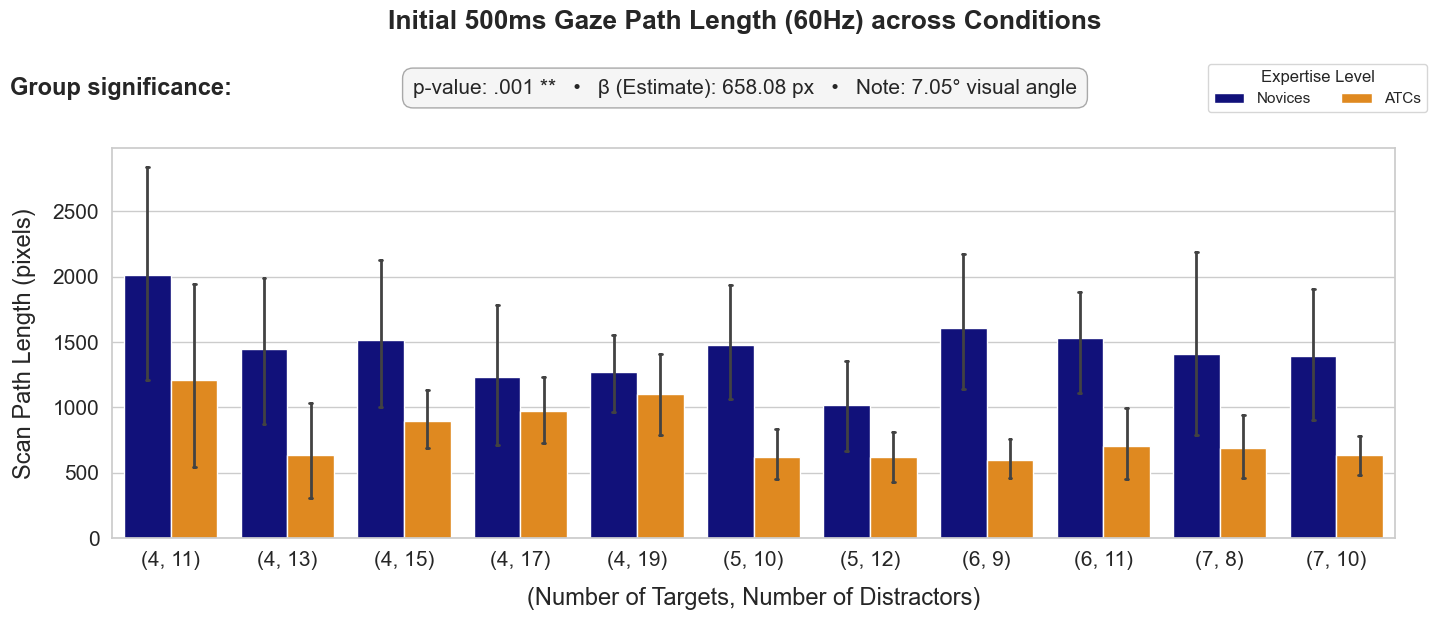

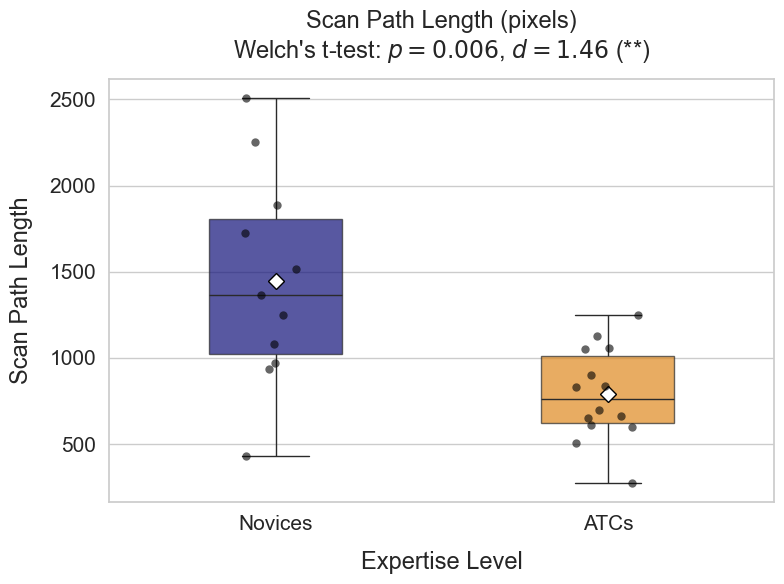

In [ ]:
def downsample_coordinates(arr, factor):
    """
    Safely downsamples a 1D numpy array using block averaging.
    Robust to NaNs (blinks) and uneven array lengths.
    """
    pad_size = (factor - (len(arr) % factor)) % factor
    if pad_size > 0:
        arr = np.concatenate([arr, np.full(pad_size, np.nan)])
        
    with np.errstate(invalid='ignore'):
        return np.nanmean(arr.reshape(-1, factor), axis=1)

def extract_path_length_hz(row, target_hz, interval_sec=0.5, orig_fs=1000):
    """
    Extracts total path length downsampled to a target frequency for a specific interval.
    """
    num_samples = int(interval_sec * orig_fs)
    x = np.array(row["xpos"][:num_samples], dtype=float)
    y = np.array(row["ypos"][:num_samples], dtype=float)
    
    # Calculate downsample factor
    factor = int(orig_fs / target_hz)
    
    x_down = downsample_coordinates(x, factor)
    y_down = downsample_coordinates(y, factor)
    
    dx_down, dy_down = np.diff(x_down), np.diff(y_down)
    path_length = np.nansum(np.sqrt(dx_down**2 + dy_down**2))
    
    return path_length

# ==========================================
# Execute the Pipeline
# ==========================================

# --- CONFIGURATION ---
TARGET_HZ = 60 
INTERVAL_SEC = 0.5
# -------------------

feature_col = f"path_length_{TARGET_HZ}Hz"
interval_ms = int(INTERVAL_SEC * 1000)

print(f"Applying {TARGET_HZ}Hz Temporal Downsampling to the first {interval_ms}ms...")

combined_df[feature_col] = combined_df.apply(
    lambda row: extract_path_length_hz(
        row, 
        target_hz=TARGET_HZ, 
        interval_sec=INTERVAL_SEC, 
        orig_fs=1000
    ), 
    axis=1
)

# Aggregate across trials
df_metric = combined_df[["participant_id", "group", "trial_id", feature_col]].copy()
df_metric["condition"] = df_metric["trial_id"] // 3
df_metric = df_metric[df_metric["condition"] != 11]


df_agg = MixedEffectStatistics.condition_aggregator(
    df=df_metric,  
    value_col=feature_col,
    agg_func=np.nanmean 
)

target_agg_col = "nanmean_" + feature_col
# --- Calculate and Print Group Averages ---
print("\n" + "="*50)
print(f" GROUP AVERAGES ({interval_ms}ms Scan Path at {TARGET_HZ}Hz)")
print("="*50)
group_means_px = df_agg.groupby('group')[target_agg_col].mean()

for grp, mean_px in group_means_px.items():
    mean_deg = utils.pixels_to_degrees(mean_px)
    print(f"{grp:w<10}: {mean_px:.1f} px  -->  {mean_deg:.2f}°")


# --- Plotting ---
fig, ax = article_plots.plot_mot_feature(
    df=df_agg, 
    feature=target_agg_col, 
    y_label="Scan Path Length (pixels)",  
    plot_title=f"Initial {interval_ms}ms Gaze Path Length ({TARGET_HZ}Hz) across Conditions",
    stat_box=path_length_stats 
)
# fig.savefig("../figures/features_per_condition/mot_scan_path_length.png", dpi=300, bbox_inches='tight')


fig, ax, per_participant_path_len = article_plots.plot_aggregated_feature(
    df=df_agg, 
    feature_col=target_agg_col, 
    y_label='Scan Path Length', 
    plot_title='Scan Path Length (pixels)'
)
# fig.savefig("../figures/aggregated_features/mot_scan_path_length.png", dpi=300, bbox_inches='tight')
# --- LMM Execution ---
results, extras = GLMs.run_pymer_lmm(df_agg, target_agg_col)    

group_coef = extras['group_coef']
group_pval = extras['group_p_value']
cond_r2 = extras.get('conditional_R2', extras.get('conditional_r2', np.nan))
marg_r2 = extras.get('marginal_R2', extras.get('marginal_r2', np.nan))

summary_metrics = [{
    "Metric": f"{TARGET_HZ}Hz Path Length",
    "Coef (px)": group_coef,
    "Coef (degrees)": utils.pixels_to_degrees(group_coef),
    "P-Value": group_pval,
    "Marginal R2": marg_r2,
    "Conditional R2": cond_r2
}]

print("\n" + "="*85)
print(" FINAL LMM SUMMARY TABLE")
print("="*85)
print(pd.DataFrame(summary_metrics).to_string(index=False))

### Combined Score

Index(['participant_id', 'group', 'mean_rms_target_dist_first_sec',
       'emp_logit', 'gmean_duration_long_ms', 'nanmean_path_length_60Hz'],
      dtype='object')
Means - Novices: -0.596, ATCs: 0.468 | Linear Diff: -1.064 | % Diff: 178.57%


C:\Users\idol\Desktop\bigProjects\EyeTrackingAnalysis\statistic_checks\article_plots.py:310: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


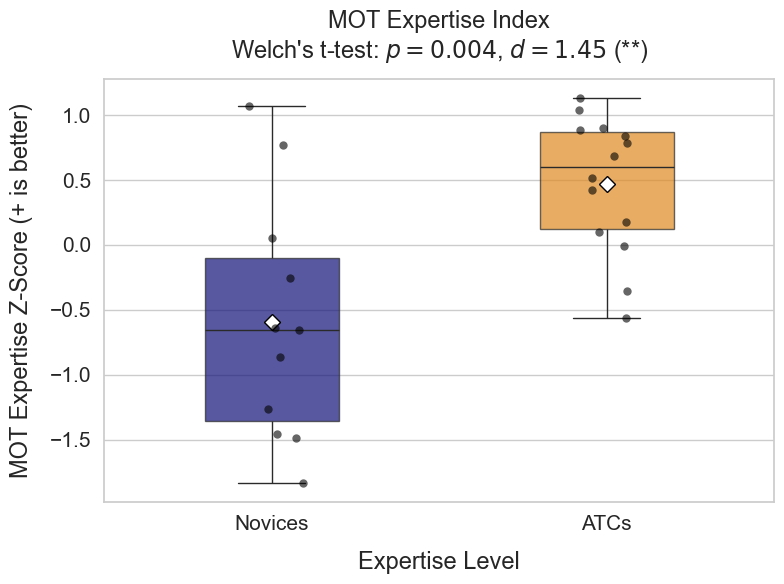

In [ ]:
from functools import reduce
from scipy.stats import zscore
# 1. Put your dataframes in a list
dfs = [per_participant_centroid_distance, per_participant_logit_accuracy, per_participant_sac_dur, per_participant_path_len]

# 2. Merge them all sequentially on the shared columns
combined_df = reduce(lambda left, right: pd.merge(left, right, on=['participant_id', 'group'], how='inner'), dfs)
print(combined_df.columns)


# 3. Apply Z-score independently to each target column
cols_to_zscore = [
    'emp_logit', 
    'mean_rms_target_dist_first_sec', 
    'gmean_duration_long_ms',
    'nanmean_path_length_60Hz'
]

# Create new z-scored columns
for col in cols_to_zscore:
    combined_df[f'{col}_z'] = zscore(combined_df[col], nan_policy='omit')

# 4. Calculate the aligned Expertise Index using the z-score columns
combined_df['expertise_index_mot'] = (
    (combined_df['emp_logit_z']) +                                  # Higher accuracy = Better (+)
    (combined_df['mean_rms_target_dist_first_sec_z'] * -1) +       # Lower distance = Better (-)
    (combined_df['nanmean_path_length_60Hz_z'] * -1) +       # Lower distance = Better (-)

    (combined_df['gmean_duration_long_ms_z'] * -1)                 # Lower duration = Better (-)
) / 4

fig, ax, _ = article_plots.plot_aggregated_feature(
    combined_df, 
    'expertise_index_mot', 
    'MOT Expertise Z-Score (+ is better)', 
    'MOT Expertise Index'
)
# fig.savefig("../figures/z_score/mot_z_score.png", dpi=300, bbox_inches='tight')

Means - Novices: -0.583, ATCs: 0.458 | Linear Diff: -1.041 | % Diff: 178.57%


C:\Users\idol\Desktop\bigProjects\EyeTrackingAnalysis\statistic_checks\article_plots.py:310: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


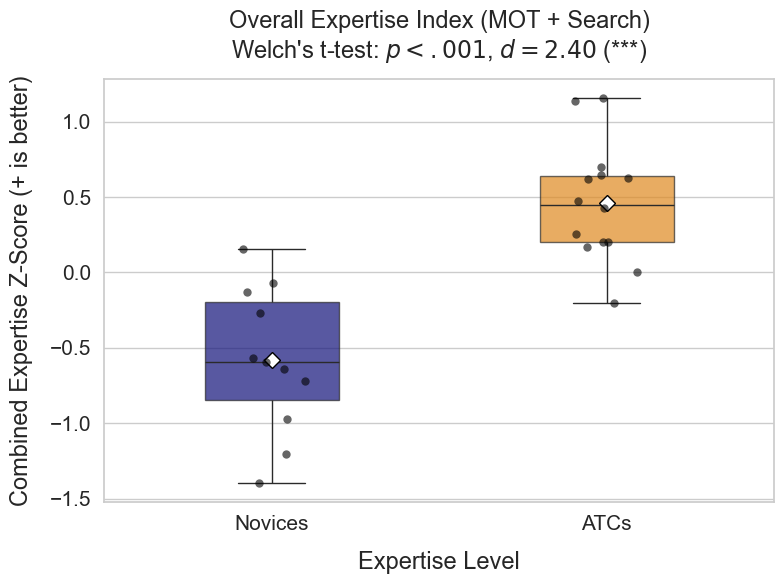

In [ ]:
importlib.reload(article_plots)
# combined_zscore_search.csv is produced by ../search_analysis/search_features.ipynb.
# It is written next to that notebook locally and into /results inside Code Ocean
# (/code is read-only there), so look in all the places it may live.
_zscore_candidates = [
    CODE_DIR / "search_analysis" / "combined_zscore_search.csv",
    Path("/results/combined_zscore_search.csv"),
    Path.cwd() / "combined_zscore_search.csv",
]
_zscore_path = next((p for p in _zscore_candidates if p.is_file()), None)
if _zscore_path is None:
    raise FileNotFoundError(
        "combined_zscore_search.csv not found - run "
        "search_analysis/search_features.ipynb first"
    )
search_zscores = pd.read_csv(_zscore_path)

# 1. Ensure participant_id is formatted consistently to prevent merge errors
combined_df['participant_id'] = combined_df['participant_id'].astype(str)
search_zscores['participant_id'] = search_zscores['participant_id'].astype(str)

# 2. Merge the MOT and Search DataFrames
final_df = pd.merge(combined_df, search_zscores, on=['participant_id', 'group'], how='inner')

# 3. Calculate the overall combined index
# Replace 'expertise_index_search' with the exact column name from your CSV if it differs
final_df['expertise_index_overall'] = (final_df['expertise_index_mot'] + final_df['expertise_index_search']) / 2

# Optional: Sort by the final index
final_df = final_df.sort_values(by='expertise_index_overall', ascending=False).reset_index(drop=True)

# 4. Plot the final combined score
fig, ax, _ = article_plots.plot_aggregated_feature(
    df=final_df, 
    feature_col='expertise_index_overall', 
    y_label='Combined Expertise Z-Score (+ is better)', 
    plot_title='Overall Expertise Index (MOT + Search)'
)

# fig.savefig("../figures/z_score/overall_z_score.png", dpi=300, bbox_inches='tight')